# 13 — IL-8 / CXCL8 as focus decision point: log2FC across all conditions

One gene (CXCL8/IL-8), its log2FC read from the DE tables we already computed, shown across
**both studies**:
- **Co-infection study** (A06): Cd vs Mock, Co vs Mock, Cd vs Co, Bt vs Mock
- **Butyrate study** (A04): Cd vs Mock at 0 / 5 / 10 mM butyrate, and the butyrate contrasts within Cd

p-value shown by star annotation + bar edge. HSPA5 added as the second readout (from the sketch).
Reads existing DE CSVs — no re-computation. Kernel: any env with pandas/matplotlib.

In [1]:
import pandas as pd, numpy as np, re, os
from pathlib import Path
import matplotlib.pyplot as plt

# --- paths (both projects live under Projects_shared) ---
A04 = Path(os.environ.get('A04_PROJ', str(Path.home()/'Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate')))
A06 = Path(os.environ.get('A06_PROJ', str(Path.home()/'Projects_shared/epithelial_coinfection-model_WORKING')))
A04T, A06T = A04/'results/tables', A06/'analysis/DE'
FIG = A04/'results/figures'; FIG.mkdir(parents=True, exist_ok=True)
print('A04 tables exist:', A04T.exists(), '| A06 DE exists:', A06T.exists())

GENES = ['CXCL8','HSPA5']            # focus gene + second readout

def sym_index(df):
    # ensure a gene-symbol index; handle Ensembl-indexed or a symbol column
    for col in ['gene_name','symbol','gene_symbol','GeneSymbol','Gene']:
        if col in df.columns:
            df = df.set_index(col); break
    df.index = [re.sub(r'\..*','',str(i)) for i in df.index]
    return df

A04 tables exist: True | A06 DE exists: True


## Read A04 (butyrate study) contrasts

In [2]:
a04_specs = [
  ('DE_Cd_vs_Mock_0mM.csv',  'Cd vs Mock\n0 mM',   'A04'),
  ('DE_Cd_vs_Mock_5mM.csv',  'Cd vs Mock\n5 mM',   'A04'),
  ('DE_Cd_vs_Mock_10mM.csv', 'Cd vs Mock\n10 mM',  'A04'),
  ('DE_Butyrate_5v0_Cd.csv', 'butyrate\n5v0 (Cd)', 'A04'),
  ('DE_Butyrate_10v0_Cd.csv','butyrate\n10v0 (Cd)','A04'),
]
def load(dirpath, fname):
    f = Path(dirpath)/fname
    if not f.exists():
        print('  MISSING', f.name); return None
    return sym_index(pd.read_csv(f, index_col=0))

rows=[]
for fn, label, study in a04_specs:
    d = load(A04T, fn)
    if d is None: continue
    for g in GENES:
        if g in d.index:
            r = d.loc[g]
            rows.append(dict(gene=g, label=label, study=study,
                             lfc=float(r.get('log2FoldChange', np.nan)),
                             padj=float(r.get('padj', np.nan))))
print('A04 rows:', len(rows))

A04 rows: 10


## Read A06 (co-infection study) contrasts

In [3]:
a06_specs = [
  ('pydeseq2_Cd_vs_Mock_annotated.csv', 'Cd vs Mock',  'A06'),
  ('pydeseq2_Co_vs_Mock_annotated.csv', 'Co vs Mock',  'A06'),
  ('pydeseq2_Cd_vs_Co_annotated.csv',   'Cd vs Co',    'A06'),
  ('pydeseq2_Bt_vs_Mock_annotated.csv', 'Bt vs Mock',  'A06'),
]
for fn, label, study in a06_specs:
    d = load(A06T, fn)
    if d is None:   # try non-annotated fallback
        d = load(A06T, fn.replace('_annotated',''))
    if d is None: continue
    for g in GENES:
        if g in d.index:
            r=d.loc[g]
            lfc = r.get('log2FoldChange', r.get('log2FC', np.nan))
            padj= r.get('padj', r.get('pvalue', np.nan))
            rows.append(dict(gene=g,label=label,study=study,lfc=float(lfc),padj=float(padj)))
df=pd.DataFrame(rows)
print('total rows:', len(df))
print(df.round(3).to_string())

total rows: 10
    gene                label study    lfc   padj
0  CXCL8     Cd vs Mock\n0 mM   A04  4.090  0.000
1  HSPA5     Cd vs Mock\n0 mM   A04  0.876  0.000
2  CXCL8     Cd vs Mock\n5 mM   A04  4.086  0.000
3  HSPA5     Cd vs Mock\n5 mM   A04  0.364  0.151
4  CXCL8    Cd vs Mock\n10 mM   A04  1.900  0.000
5  HSPA5    Cd vs Mock\n10 mM   A04  0.381  0.137
6  CXCL8   butyrate\n5v0 (Cd)   A04 -0.925  0.034
7  HSPA5   butyrate\n5v0 (Cd)   A04 -0.914  0.001
8  CXCL8  butyrate\n10v0 (Cd)   A04 -3.734  0.000
9  HSPA5  butyrate\n10v0 (Cd)   A04 -1.489  0.000


## Figure: CXCL8 log2FC across all conditions (p-value stars)

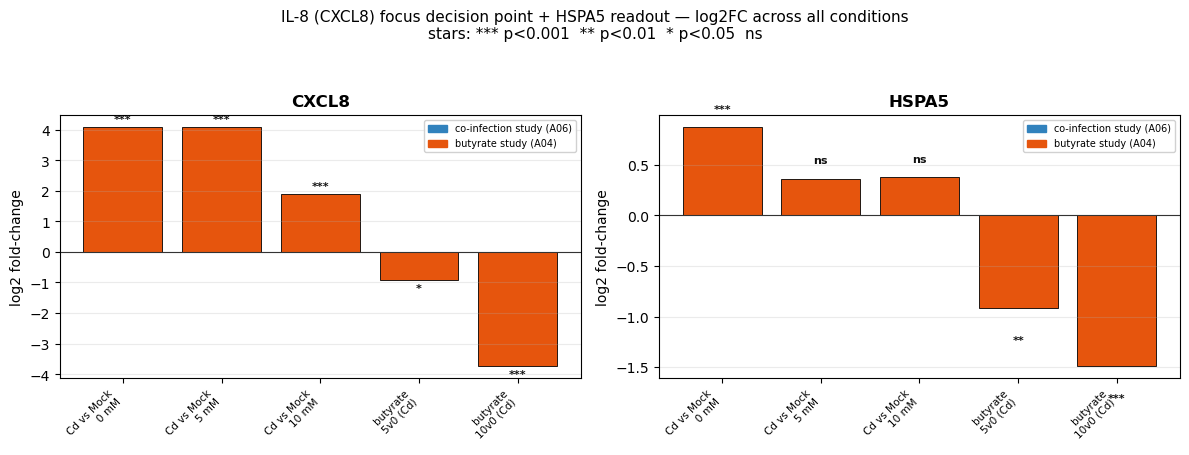

wrote /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/figures/CXCL8_focus_across_conditions.png


In [4]:
def stars(p):
    if pd.isna(p): return 'ns'
    return '***' if p<1e-3 else '**' if p<1e-2 else '*' if p<0.05 else 'ns'

def plot_gene(g, ax):
    sub=df[df.gene==g].reset_index(drop=True)
    # order: A06 block then A04 block, in the spec order above
    order=['Cd vs Mock','Co vs Mock','Cd vs Co','Bt vs Mock',
           'Cd vs Mock\n0 mM','Cd vs Mock\n5 mM','Cd vs Mock\n10 mM',
           'butyrate\n5v0 (Cd)','butyrate\n10v0 (Cd)']
    sub['ord']=sub.label.apply(lambda l: order.index(l) if l in order else 99)
    sub=sub.sort_values('ord')
    x=range(len(sub))
    cols=['#3182bd' if s=='A06' else '#e6550d' for s in sub.study]
    bars=ax.bar(x, sub.lfc, color=cols, edgecolor='k', lw=.6)
    for xi,(_,r) in zip(x,sub.iterrows()):
        y=r.lfc; off=0.15 if y>=0 else -0.35
        ax.text(xi, y+off, stars(r.padj), ha='center', fontsize=8,
                fontweight='bold', color='#111')
    ax.axhline(0,color='#333',lw=.8)
    ax.set_xticks(list(x)); ax.set_xticklabels(sub.label, rotation=45, ha='right', fontsize=7.5)
    ax.set_ylabel('log2 fold-change'); ax.set_title(f'{g}', fontsize=12, fontweight='bold')
    ax.grid(axis='y', alpha=.25)
    # study separators / legend
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color='#3182bd',label='co-infection study (A06)'),
                       Patch(color='#e6550d',label='butyrate study (A04)')],
              fontsize=7, loc='best', framealpha=.9)

fig,axes=plt.subplots(1,2,figsize=(12,4.6))
plot_gene('CXCL8', axes[0])
plot_gene('HSPA5', axes[1])
fig.suptitle('IL-8 (CXCL8) focus decision point + HSPA5 readout — log2FC across all conditions\nstars: *** p<0.001  ** p<0.01  * p<0.05  ns',
             fontsize=11)
plt.tight_layout(rect=[0,0,1,0.93])
fig.savefig(FIG/'CXCL8_focus_across_conditions.png', dpi=150, bbox_inches='tight')
plt.show(); print('wrote', FIG/'CXCL8_focus_across_conditions.png')

## Notes
- Blue = co-infection study contrasts, orange = butyrate study contrasts. Direct log2FC comparison
  of the same gene across both models and all butyrate doses.
- CXCL8 storyline expected: strongly UP with Cd; attenuated in Co (A06) and with butyrate dose (A04).
- HSPA5 storyline: UP with infection, down with butyrate — the dissociation, in one gene.
- If A06 column names differ (log2FC vs log2FoldChange), the loader already handles both; if a
  gene is absent from a table it's skipped (printed above).